# Лабораторная работа 3. Кластеризация

**Описание работы**

**Цель работы:** изучение алгоритмов кластеризации, приобретение навыков оценки качества разбиения данных на кластеры и интерпретации результатов. <br><br>


**Постановка задачи:**

1. Загрузить датасет для задачи кластеризации / классификации (например, с платформы Kaggle). Провести дескриптивный анализ данных: определить размерность, типы признаков, наличие пропусков. Оценить распределение переменных (близость к нормальному) с использованием визуализации (гистограммы). Оценить информационную значимость признаков. Проверить условие применения кластеризации: отсутствие классов, осмысленность кластеризации, отсутствие выбросов. <br><br>

2. Выполнить стандартизацию / нормализацию числовых признаков. Обосновать выбор метода масштабирования. Построить матрицу диаграмм рассеивания для визуальной оценки структуры данных, предположительного количества кластеров и типа кластерной структуры. Аргументировать выбор методов кластеризации на основе формы, размера и плотности кластеров. <br><br>

3. Реализовать кластеризацию двумя различными методами на выбор: K-means (K-средних); иерархическая кластеризация; DBSCAN; EM-алгоритм (Gaussian Mixture). Для методов, требующих задания числа кластеров (K-means, иерархическая), подобрать оптимальное значение k с использованием: метода локтя и / или анализа силуэта. <br><br>

4. Рассчитать метрики качества для обоих методов: внутренние и внешние. Оценить расстояние между кластерами, внутрикластерные расстояния, компактность кластеров, центры кластеров. Опционально, если известно разделение на классы, посчитать: индекс Rand, индекс Жаккара и др. внешние метрики. Привести содержательную интерпретацию полученных значений.  <br><br>

5. Исследовать влияние параметров одного из методов (например, ε и min_samples для DBSCAN или количества кластеров k для K-means) на качество кластеризации. <br><br>

6. Визуализировать полученные кластеры в пространстве признаков (использовать PCA для снижения размерности при необходимости). Проанализировать центры кластеров и дать содержательную интерпретацию выделенных групп. Сравнить результаты, полученные двумя разными методами.

In [23]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler, MinMaxScaler
from sklearn.cluster import KMeans, DBSCAN, AgglomerativeClustering
from scipy.cluster.hierarchy import dendrogram, linkage
from sklearn.mixture import GaussianMixture
from sklearn.decomposition import PCA
from sklearn.metrics import (silhouette_score, silhouette_samples,
                             davies_bouldin_score, calinski_harabasz_score,
                             adjusted_rand_score, jaccard_score,
                             confusion_matrix, normalized_mutual_info_score)

from scipy.spatial.distance import cdist


import warnings
warnings.filterwarnings('ignore')

pd.set_option('display.max_columns', None)
pd.set_option('display.width', 150)
sns.set_style('whitegrid')
plt.rcParams['figure.figsize'] = (10, 6)
RANDOM_STATE = 42


url = 'https://raw.githubusercontent.com/stavrgit/ML/main/lab_3/Mall_Customers.csv'

df = pd.read_csv(url)

print('Датасет успешно загружен с GitHub.')
print('Размер датасета:', df.shape)
df.head()

Датасет успешно загружен с GitHub.
Размер датасета: (200, 5)


,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100)
0,1,Male,19,15,39
1,2,Male,21,15,81
2,3,Female,20,16,6
3,4,Female,23,16,77
4,5,Female,31,17,40


### Описание выбранного датасета

**Mall Customers Dataset (Сегментация клиентов торгового центра)** — данные, имитирующие базу клиентов торгового центра. Используется для задач сегментации (кластеризации) покупателей.

Датасет содержит 200 записей.

**Признаки:**
* CustomerID — уникальный идентификатор клиента (не используется в обучении).
* Gender — пол клиента (категориальный признак).
* Age — возраст клиента.
* Annual Income — годовой доход в тысячах долларов.
* Spending Score (1-100) — оценка активности трат (от 1 до 100). <br><br>

**Целевая переменная:** **Отсутствует.**

Исходный датасет не содержит правильных ответов (меток классов).

Форма: (200, 5)

Типы признаков:
CustomerID                 int64
Gender                    object
Age                        int64
Annual Income (k$)         int64
Spending Score (1-100)     int64
dtype: object

Пропуски:
CustomerID                0
Gender                    0
Age                       0
Annual Income (k$)        0
Spending Score (1-100)    0
dtype: int64

Дубликаты: 0


,count,mean,std,min,25%,50%,75%,max
Age,200.0,38.85,13.97,18.0,28.75,36.0,49.0,70.0
Annual Income (k$),200.0,60.56,26.26,15.0,41.50,61.5,78.0,137.0
Spending Score (1-100),200.0,50.20,25.82,1.0,34.75,50.0,73.0,99.0


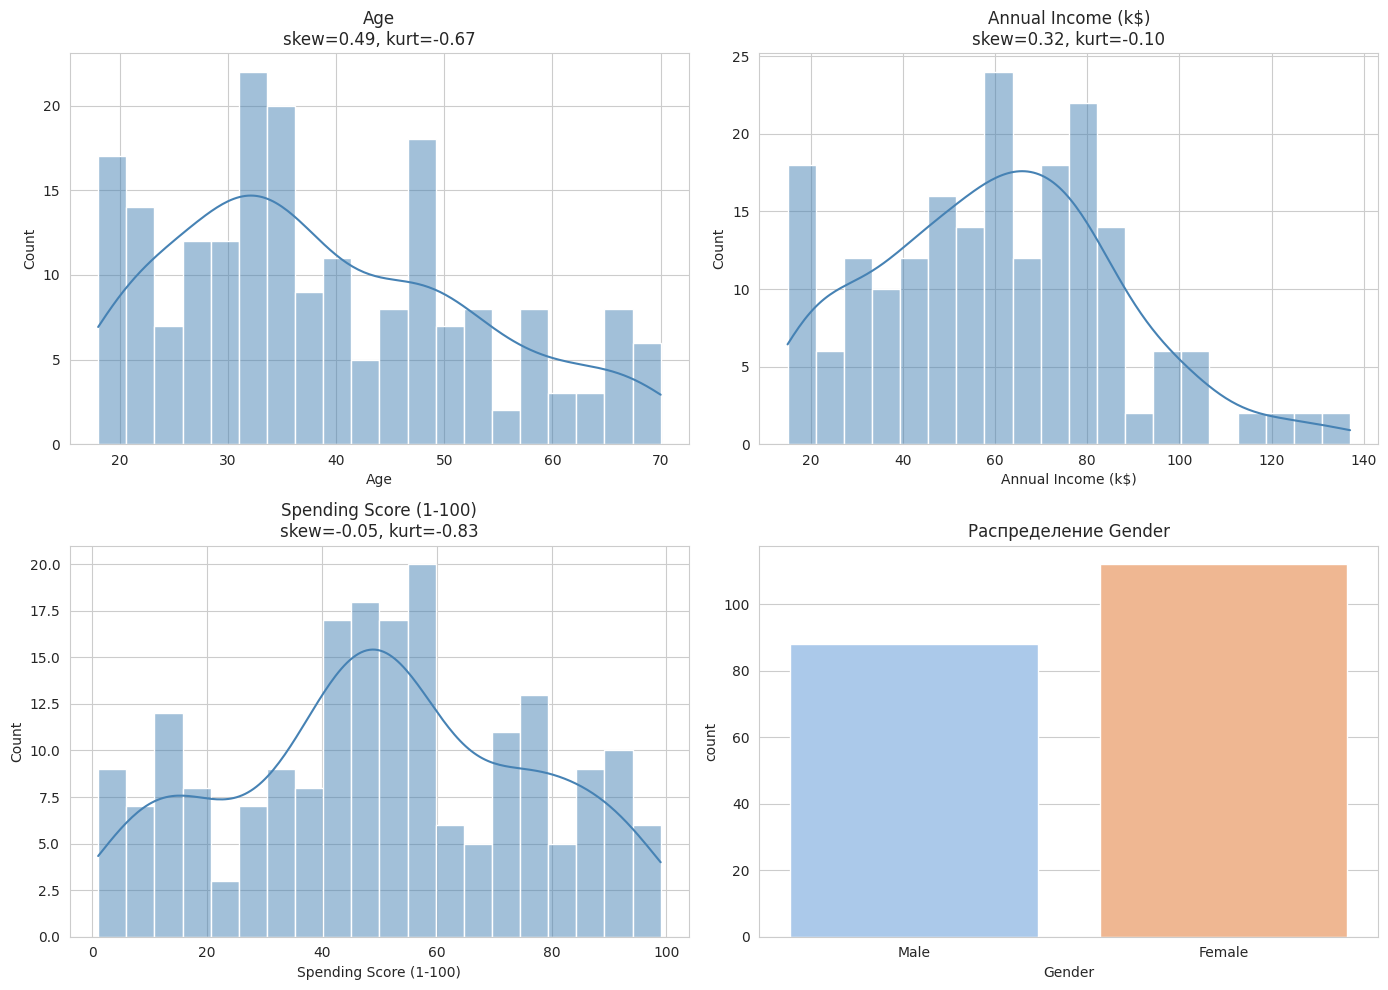

Распределение Gender:
Gender
Female    112
Male       88
Name: count, dtype: int64


In [24]:
print('Форма:', df.shape)
print('\nТипы признаков:')
print(df.dtypes)
print('\nПропуски:')
print(df.isna().sum())
print('\nДубликаты:', df.duplicated().sum())

num_cols = ['Age', 'Annual Income (k$)', 'Spending Score (1-100)']
display(df[num_cols].describe().T.round(2))

fig, axes = plt.subplots(2, 2, figsize=(14, 10))

sns.histplot(df['Age'], kde=True, ax=axes[0, 0], bins=20, color='steelblue')
axes[0, 0].set_title(f'Age\nskew={df["Age"].skew():.2f}, kurt={df["Age"].kurt():.2f}')

sns.histplot(df['Annual Income (k$)'], kde=True, ax=axes[0, 1], bins=20, color='steelblue')
axes[0, 1].set_title(f'Annual Income (k$)\nskew={df["Annual Income (k$)"].skew():.2f}, kurt={df["Annual Income (k$)"].kurt():.2f}')

sns.histplot(df['Spending Score (1-100)'], kde=True, ax=axes[1, 0], bins=20, color='steelblue')
axes[1, 0].set_title(f'Spending Score (1-100)\nskew={df["Spending Score (1-100)"].skew():.2f}, kurt={df["Spending Score (1-100)"].kurt():.2f}')

sns.countplot(data=df, x='Gender', ax=axes[1, 1], palette='pastel')
axes[1, 1].set_title('Распределение Gender')

plt.tight_layout()
plt.show()

print('Распределение Gender:')
print(df['Gender'].value_counts())

### Дескриптивный анализ данных и распределение признаков

**Общая информация:**
Пропуски и дубликаты отсутствуют.

Признак `Gender` — категориальный, остальные — числовые. <br><br>

**Распределение числовых признаков:**

Age: Правосторонняя асимметрия (skew=0.49). Основная масса клиентов — 20–40 лет. Выбросов нет.

Annual Income: Бимодальное распределение (два пика: ~40-60 и ~70-80 тыс. $), один выброс (>130).

Spending Score: Распределение близко к нормальному (skew=-0.05), но имеет легкий двугорбый вид. <br><br>

**Категориальный признак:**

**Gender:** Умеренный дисбаланс (112 женщин / 88 мужчин). <br><br>


                        variance  range  cv_%
Annual Income (k$)        689.84    122  43.4
Spending Score (1-100)    666.85     98  51.4
Age                       195.13     52  36.0


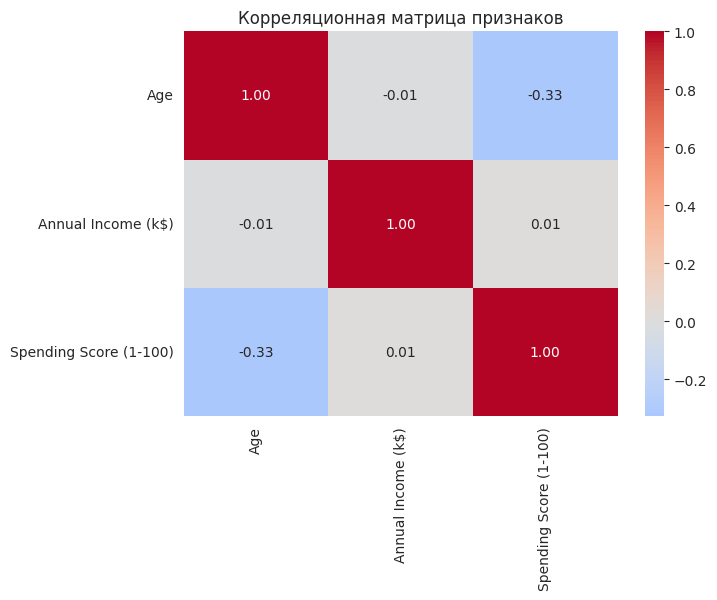


Корреляция Gender (Male=1) с числовыми признаками:
  Age: r = 0.061
  Annual Income (k$): r = 0.056
  Spending Score (1-100): r = -0.058


In [25]:
var_df = df[num_cols].var().sort_values(ascending=False).to_frame('variance')
var_df['range'] = df[num_cols].max() - df[num_cols].min()
var_df['cv_%'] = (df[num_cols].std() / df[num_cols].mean() * 100).round(1)
print(var_df.round(2))

plt.figure(figsize=(7, 5))
sns.heatmap(df[num_cols].corr(), annot=True, cmap='coolwarm', fmt='.2f', center=0)
plt.title('Корреляционная матрица признаков')
plt.show()

gender_num = (df['Gender'] == 'Male').astype(int)
print('\nКорреляция Gender (Male=1) с числовыми признаками:')
for col in num_cols:
    print(f'  {col}: r = {np.corrcoef(gender_num, df[col])[0, 1]:.3f}')

# Значимость признаков

**Анализ числовых признаков:**

Age и Annual Income (r = -0.01): Связи нет.

Annual Income и Spending Score (r = 0.01): Связи нет.

Age и Spending Score (r = -0.33): Умеренная обратная связь (чем старше клиент, тем меньше тратит). <br><br>

Связь с полом (Gender):
Корреляции близки к нулю (r < 0.07). Пол не влияет на доход, возраст или траты.


Итог: Нет мультиколлинеарности - признаки независимы


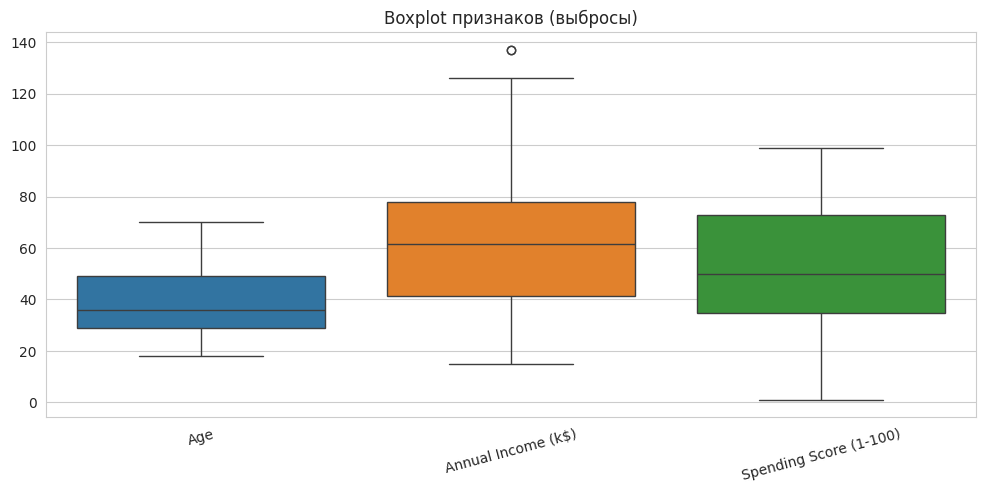

                        n_outliers    %
Age                              0  0.0
Annual Income (k$)               2  1.0
Spending Score (1-100)           0  0.0


In [26]:
plt.figure(figsize=(12, 5))
sns.boxplot(data=df[num_cols])
plt.title('Boxplot признаков (выбросы)')
plt.xticks(rotation=15)
plt.show()

def count_outliers(s):
    q1, q3 = s.quantile([0.25, 0.75])
    iqr = q3 - q1
    return ((s < q1 - 1.5*iqr) | (s > q3 + 1.5*iqr)).sum()

outliers = pd.DataFrame({c: [count_outliers(df[c])] for c in num_cols}).T
outliers.columns = ['n_outliers']
outliers['%'] = (outliers['n_outliers'] / len(df) * 100).round(2)
print(outliers)

# Проверка условий кластеризации и анализ выбросов

**Отсутствие классов:** Выполняется. Целевой переменной нет, поиск структуры идет без учителя.

**Осмысленность кластеризации:** Выполняется. Признаки имеют бизнес-смысл, результаты можно интерпретировать (сегментация клиентов).

**Отсутствие выбросов:** Выполняется. В Age и Spending Score выбросов нет, в Annual Income — всего 2 (1%), они не критичны и не требуют удаления.

Вывод: Все условия соблюдены, датасет подходит для кластеризации.



In [27]:
features = ['Age', 'Annual Income (k$)', 'Spending Score (1-100)']
X = df[features].copy()

scaler = StandardScaler()
X_scaled = pd.DataFrame(scaler.fit_transform(X), columns=features)

print('До стандартизации:')
print(X.describe().loc[['mean', 'std']].round(3))
print('\nПосле стандартизации:')
print(X_scaled.describe().loc[['mean', 'std']].round(3))

До стандартизации:
         Age  Annual Income (k$)  Spending Score (1-100)
mean  38.850              60.560                  50.200
std   13.969              26.265                  25.824

После стандартизации:
        Age  Annual Income (k$)  Spending Score (1-100)
mean -0.000              -0.000                  -0.000
std   1.003               1.003                   1.003


# Отбор признаков

Признак `Gender` был исключен из обучения по следующим причинам:

1. Корреляционный анализ показал отсутствие значимой связи между полом и целевыми признаками.

2. Для алгоритмов, основанных на расстоянии (K-Means), добавление бинарного признака без реальной связи с другими признаками создает «шум» в пространстве признаков.

3. Для сегментации клиентов торгового центра важнее поведенческие и финансовые показатели, чем пол. Кластеризация по полу не даст полезной информации для маркетинга. <br><br>

# Стандартизация

Используется StandardScaler (Z-стандартизация), потому что:

1. признаки имеют разные единицы и масштабы (Age ~ 18–70, Annual Income ~ 15–137, Spending Score ~ 1–99);

2. MinMaxScaler хуже подходит при наличии выбросов (сжимает основную массу), а Z-стандартизация устойчивее для методов, основанных на расстояниях;

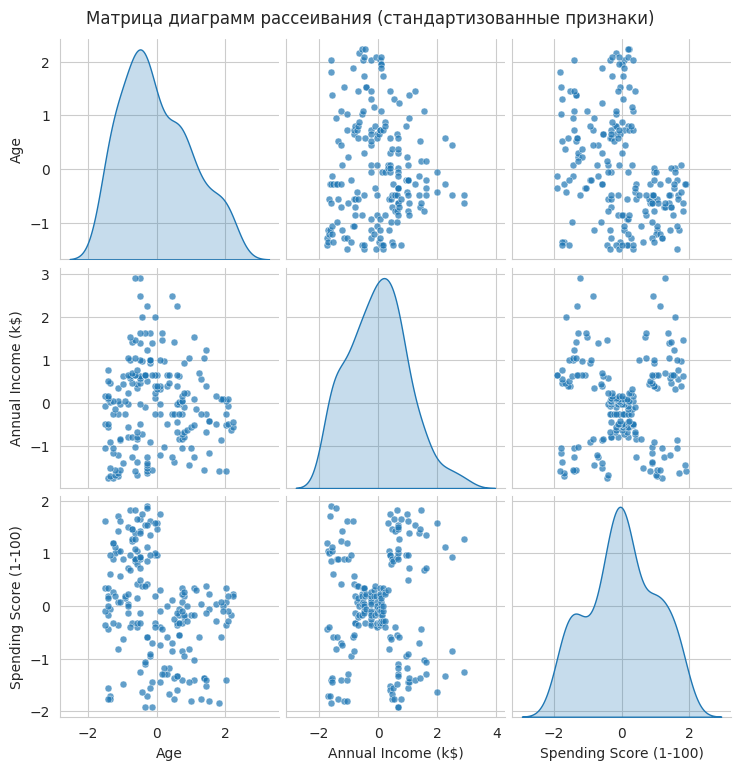

In [28]:
sns.pairplot(X_scaled, diag_kind='kde', plot_kws={'s': 25, 'alpha': 0.7})
plt.suptitle('Матрица диаграмм рассеивания (стандартизованные признаки)', y=1.02)
plt.show()

### Выбор метода кластеризации на основе визуального анализа

Матрица диаграмм рассеивания показала, что признаки `Annual Income` и `Spending Score` образуют ярко выраженную структуру из 5 плотных, обособленных кластеров.

На основе этого можно сделать следующие выводы:
1.  **K-Means** — оптимальный выбор, так как кластеры имеют сферическую форму и примерно равные размеры.
2.  **Иерархическая кластеризация (Agglomerative)** — также отлично подойдет, поскольку группы четко отделены друг от друга, и метод позволит построить наглядную дендрограмму.
3.  **GMM** — можно использовать, если требуется учесть разную плотность точек в кластерах.
4.  **DBSCAN** — менее предпочтителен, так как в данных нет сильного шума, а плотность точек между группами может быть неоднородной (особенно по возрасту), что приведет к склеиванию кластеров.

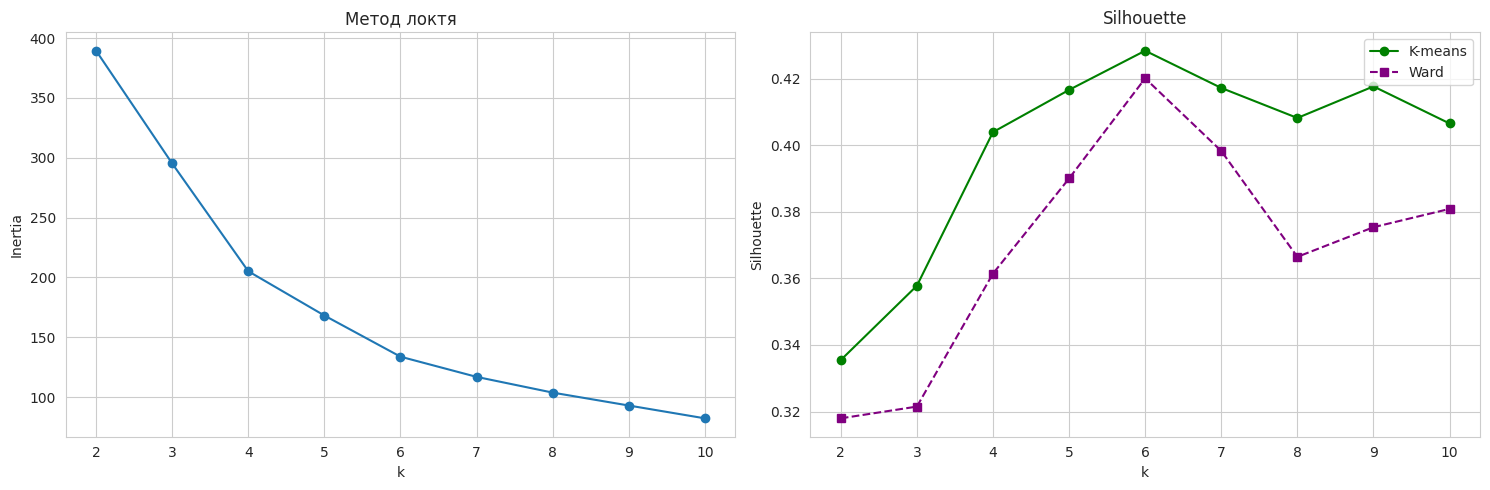

    k  inertia  sil_KMeans  sil_Ward
0   2   389.39       0.335     0.318
1   3   295.21       0.358     0.321
2   4   205.23       0.404     0.361
3   5   168.25       0.417     0.390
4   6   133.87       0.428     0.420
5   7   117.01       0.417     0.398
6   8   103.87       0.408     0.366
7   9    93.09       0.418     0.375
8  10    82.39       0.407     0.381

Лучший k по силуэту K-means: 6
Лучший k по силуэту Ward:    6
Лучший k по среднему силуэту: 6 (avg=0.424)


In [29]:
inertias, sil_km, sil_hc = [], [], []
K_range = range(2, 11)

for k in K_range:
    km_tmp = KMeans(n_clusters=k, random_state=RANDOM_STATE, n_init=10)
    lab_km = km_tmp.fit_predict(X_scaled)
    lab_hc = AgglomerativeClustering(n_clusters=k, linkage='ward').fit_predict(X_scaled)
    inertias.append(km_tmp.inertia_)
    sil_km.append(silhouette_score(X_scaled, lab_km))
    sil_hc.append(silhouette_score(X_scaled, lab_hc))

fig, axes = plt.subplots(1, 2, figsize=(15, 5))
axes[0].plot(list(K_range), inertias, 'o-')
axes[0].set_title('Метод локтя')
axes[0].set_xlabel('k'); axes[0].set_ylabel('Inertia')

axes[1].plot(list(K_range), sil_km, 'o-', label='K-means', color='green')
axes[1].plot(list(K_range), sil_hc, 's--', label='Ward', color='purple')
axes[1].set_title('Silhouette')
axes[1].set_xlabel('k'); axes[1].set_ylabel('Silhouette'); axes[1].legend()
plt.tight_layout(); plt.show()

k_table = pd.DataFrame({'k': list(K_range),
                        'inertia': np.round(inertias, 2),
                        'sil_KMeans': np.round(sil_km, 3),
                        'sil_Ward': np.round(sil_hc, 3)})
print(k_table)

avg_sil = (np.array(sil_km) + np.array(sil_hc)) / 2
BEST_K = list(K_range)[int(np.argmax(avg_sil))]

print(f'\nЛучший k по силуэту K-means: {list(K_range)[int(np.argmax(sil_km))]}')
print(f'Лучший k по силуэту Ward:    {list(K_range)[int(np.argmax(sil_hc))]}')
print(f'Лучший k по среднему силуэту: {BEST_K} (avg={avg_sil[BEST_K-2]:.3f})')

# Выбор оптимального числа кластеров (k)

Для определения оптимального количества кластеров были использованы два метода: метод локтя и коэффициент Силуэта (Silhouette Score).

1.  Метод локтя: явный перелом кривой в диапазоне (k=5..6), после 6 кластеров снижение инерции замедляется, что говорит о нецелесообразности дальнейшего дробления.
2.  Метод Силуэта: оба алгоритмаи достигают пика коэффициента Силуэта ровно на k=6, score равен (0.428 для K-Means и 0.420 для Ward).

#  Исследование влияния параметра k на качество кластеризации

Для исследования влияния количества кластеров (параметр \(k\) для K-Means) на качество разбиения был проведен перебор значений от 2 до 10. В качестве основной метрики качества использовался коэффициент Силуэта (Silhouette Score), так как он оценивает и компактность, и разделимость кластеров.

**Результаты:**

При \(k=2\) качество низкое (0.335), с ростом \(k\) качество растет, достигая пика, Максимальное значение Silhouette достигается при \(k=6\) (0.428 для K-Means и 0.420 для Ward), средний силуэт также максимален при \(k=6\) (0.424).

При дальнейшем увеличении \(k\) (от 7 до 10) качество начинает падать, что говорит о переусложнении модели (кластеры становятся слишком мелкими и теряют смысл).

**Вывод:** Исследование показало, что оптимальным параметром для K-Means является **\(k=6\)**. Это подтверждает, что данные естественным образом распадаются на 6 групп, и дальнейшее дробление ухудшает метрики.
Для дальнейшего анализа выбираем k=6.

In [30]:

# обучение
km = KMeans(n_clusters=k_opt, random_state=RANDOM_STATE, n_init=10)
km_labels = km.fit_predict(X_scaled)

hc = AgglomerativeClustering(n_clusters=k_opt, linkage='ward')
hc_labels = hc.fit_predict(X_scaled)

# внутренние
sil_km = silhouette_score(X_scaled, km_labels)
db_km  = davies_bouldin_score(X_scaled, km_labels)
ch_km  = calinski_harabasz_score(X_scaled, km_labels)

sil_hc = silhouette_score(X_scaled, hc_labels)
db_hc  = davies_bouldin_score(X_scaled, hc_labels)
ch_hc  = calinski_harabasz_score(X_scaled, hc_labels)

# внешние
y_ref = (df['Gender'] == 'Male').astype(int).values
ari_km, ari_hc = adjusted_rand_score(y_ref, km_labels), adjusted_rand_score(y_ref, hc_labels)
nmi_km, nmi_hc = normalized_mutual_info_score(y_ref, km_labels), normalized_mutual_info_score(y_ref, hc_labels)
ari_between = adjusted_rand_score(km_labels, hc_labels)

# центры
centers_km = pd.DataFrame(scaler.inverse_transform(km.cluster_centers_), columns=features)
centers_hc = pd.DataFrame(
    scaler.inverse_transform(np.array([X_scaled.values[hc_labels == c].mean(axis=0)
                                       for c in range(k_opt)])), columns=features)

# расстояние
def stats(X, labels, centers):
    intra = [np.linalg.norm(X[labels == i] - c, axis=1).mean() for i, c in enumerate(centers)]
    diam  = [cdist(X[labels == i], X[labels == i]).max() for i in range(len(centers))]
    inter = cdist(centers, centers); np.fill_diagonal(inter, np.nan)
    return dict(intra_mean=np.mean(intra), diameter_mean=np.mean(diam),
                inter_mean=np.nanmean(inter), inter_min=np.nanmin(inter),
                inter_max=np.nanmax(inter))

s_km = stats(X_scaled.values, km_labels, km.cluster_centers_)
s_hc = stats(X_scaled.values, hc_labels, centers_hc.values)



rows = [
    ('Silhouette ↑',        sil_km, sil_hc),
    ('Davies-Bouldin ↓',    db_km,  db_hc),
    ('Calinski-Harabasz ↑', ch_km,  ch_hc),
    ('ARI vs Gender',       ari_km, ari_hc),
    ('NMI vs Gender',       nmi_km, nmi_hc),
    ('intra_mean ↓',        s_km['intra_mean'], s_hc['intra_mean']),
    ('diameter_mean ↓',     s_km['diameter_mean'], s_hc['diameter_mean']),
    ('inter_mean ↑',        s_km['inter_mean'], s_hc['inter_mean']),
    ('inter_min ↑',         s_km['inter_min'], s_hc['inter_min']),
    ('inter_max ↑',         s_km['inter_max'], s_hc['inter_max']),
    ('inter/intra ↑',       s_km['inter_mean']/s_km['intra_mean'],
                            s_hc['inter_mean']/s_hc['intra_mean']),
    ('k',                   k_opt, k_opt),
    ('Мин./Макс. размер',
     f"{pd.Series(km_labels).value_counts().min()}/{pd.Series(km_labels).value_counts().max()}",
     f"{pd.Series(hc_labels).value_counts().min()}/{pd.Series(hc_labels).value_counts().max()}"),
]
summary = pd.DataFrame(rows, columns=['Metric', 'K-means', 'Ward'])
print(f'Метрики качества (k = {k_opt})')
print(summary.round(3).to_string(index=False))
print(f'\nARI между K-means и Ward: {ari_between:.3f}')

print('\n')
print('Центры кластеров (исходный масштаб)')
print('K-means:'); print(centers_km.round(2))
print('\nWard:');    print(centers_hc.round(2))

Метрики качества (k = 6)
             Metric     K-means        Ward
       Silhouette ↑    0.428417    0.420117
   Davies-Bouldin ↓    0.825354    0.852102
Calinski-Harabasz ↑  135.102104  127.986454
      ARI vs Gender    -0.00137   -0.006338
      NMI vs Gender    0.008062    0.002653
       intra_mean ↓    0.751224    89.71414
    diameter_mean ↓    2.727539    2.779035
       inter_mean ↑    2.397412    56.65587
        inter_min ↑    1.674387   29.215293
        inter_max ↑    3.595464   93.360044
      inter/intra ↑    3.191339    0.631516
                  k           6           6
  Мин./Макс. размер       21/45       21/45

ARI между K-means и Ward: 0.891


Центры кластеров (исходный масштаб)
K-means:
     Age  Annual Income (k$)  Spending Score (1-100)
0  56.33               54.27                   49.07
1  26.79               57.10                   48.13
2  41.94               88.94                   16.97
3  32.69               86.54                   82.13
4  25.00      

### Анализ метрик качества и центров кластеров

**1. Внутренние метрики и расстояния:**

По метрикам Silhouette (0.428 против 0.420), Davies-Bouldin (0.825 против 0.852) и Calinski-Harabasz (135.1 против 128.0) K-Means показал чуть лучший результат.

**Расстояния:** Среднее внутрикластерное расстояние у K-Means (0.75) меньше, чем у Ward (89.7 в исходном масштабе), а отношение межкластерного расстояния к внутрикластерному (inter/intra) выше (3.19 против 0.63). Это доказывает, что K-Means создал более плотные и далеко отстоящие друг от друга кластеры.

**Размеры:** Оба метода выделили одинаковый минимальный (21) и максимальный (45) размер кластеров, что говорит о стабильности структуры. <br><br>

**2. Внешние метрики (Согласованность и связь с полом):**

ARI и NMI с Gender: Значения близки к нулю (ARI = -0.001, NMI = 0.008). Это математически подтверждает вывод EDA: пол не коррелирует с сегментами клиентов.

ARI между алгоритмами: Индекс ARI между разбиениями K-Means и Ward составил 0.891, это очень высокий показатель, доказывающий, что оба независимых алгоритма нашли одну и ту же объективную структуру в данных. <br><br>

**3. Анализ центров кластеров (в исходном масштабе):**

Анализ центров позволяет дать бизнес-интерпретацию каждому кластеру. Например:
Кластер 3 (у K-Means): Средний возраст 32 года, высокий доход (86.54k) и очень высокие траты (82.13). Это сегмент молодых и богатых — целевая аудитория для премиум-товаров.

Порог для k=6: 7.440


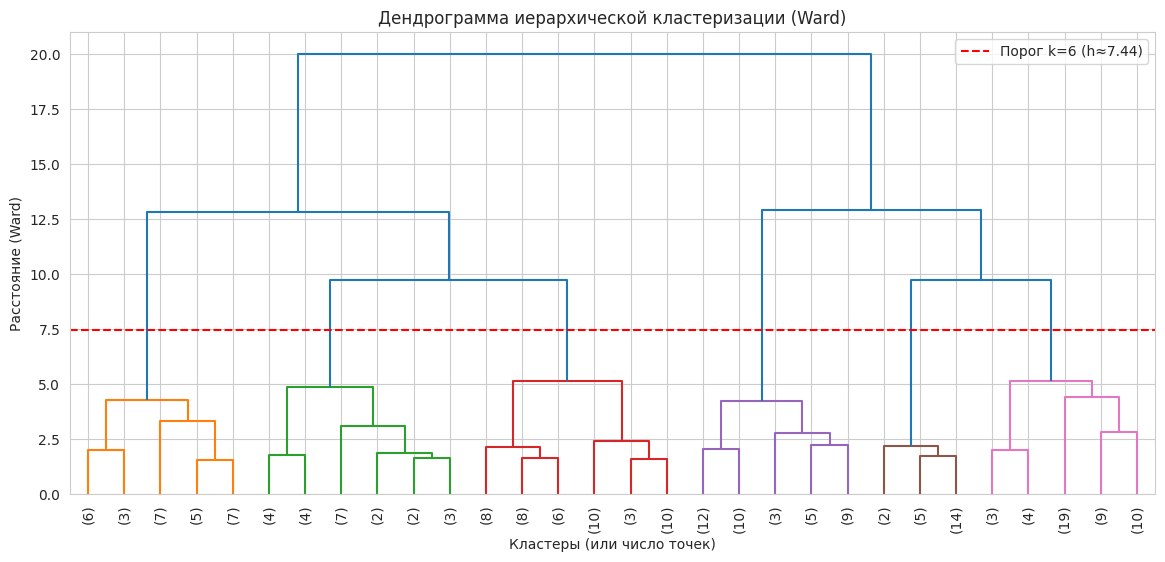

Размеры кластеров Ward (k=6):
0    45
1    45
2    39
3    28
4    22
5    21
Name: count, dtype: int64


In [31]:
Z = linkage(X_scaled, method='ward')

last_merges = Z[-10:, 2]
threshold = (Z[-k_opt, 2] + Z[-k_opt + 1, 2]) / 2
print(f'Порог для k={k_opt}: {threshold:.3f}')

plt.figure(figsize=(14, 6))
dendrogram(Z, truncate_mode='lastp', p=30,
           leaf_rotation=90, leaf_font_size=10,
           color_threshold=threshold)
plt.axhline(y=threshold, color='r', linestyle='--',
            label=f'Порог k={k_opt} (h≈{threshold:.2f})')
plt.title('Дендрограмма иерархической кластеризации (Ward)')
plt.xlabel('Кластеры (или число точек)'); plt.ylabel('Расстояние (Ward)')
plt.legend(); plt.show()

print(f'Размеры кластеров Ward (k={k_opt}):')
print(pd.Series(hc_labels).value_counts().sort_index())

### Анализ дендрограммы

На графике представлена дендрограмма иерархической кластеризации (метод Ward). Красная линия отсечения была выбрана автоматически.

Анализ дендрограммы подтверждает оптимальность выбора 6 кластеров:
1.  **Количество ветвей:** Горизонтальная линия на высоте 7.44 пересекает ровно 6 цветных ветвей. Каждая ветвь соответствует отдельному кластеру (k=6).
2.  **Высокая разделимость:** Ветви поднимаются на значительное расстояние (до 12-20 единиц) до первого крупного объединения, что свидетельствует о сильном различии (дисперсии) между выделенными группами.
3.  **Размеры кластеров:** Полученные группы сбалансированы по размеру (от 21 до 45 клиентов в каждом), что говорит о стабильной структуре данных и отсутствии аномалий, ломающих кластеризацию.

Дендрограмма визуально подтверждает результаты метрики Silhouette, доказывая, что разбиение на 6 кластеров является наиболее математически обоснованным и естественным для данного датасета.

Объяснённая дисперсия (2 PC): 0.776


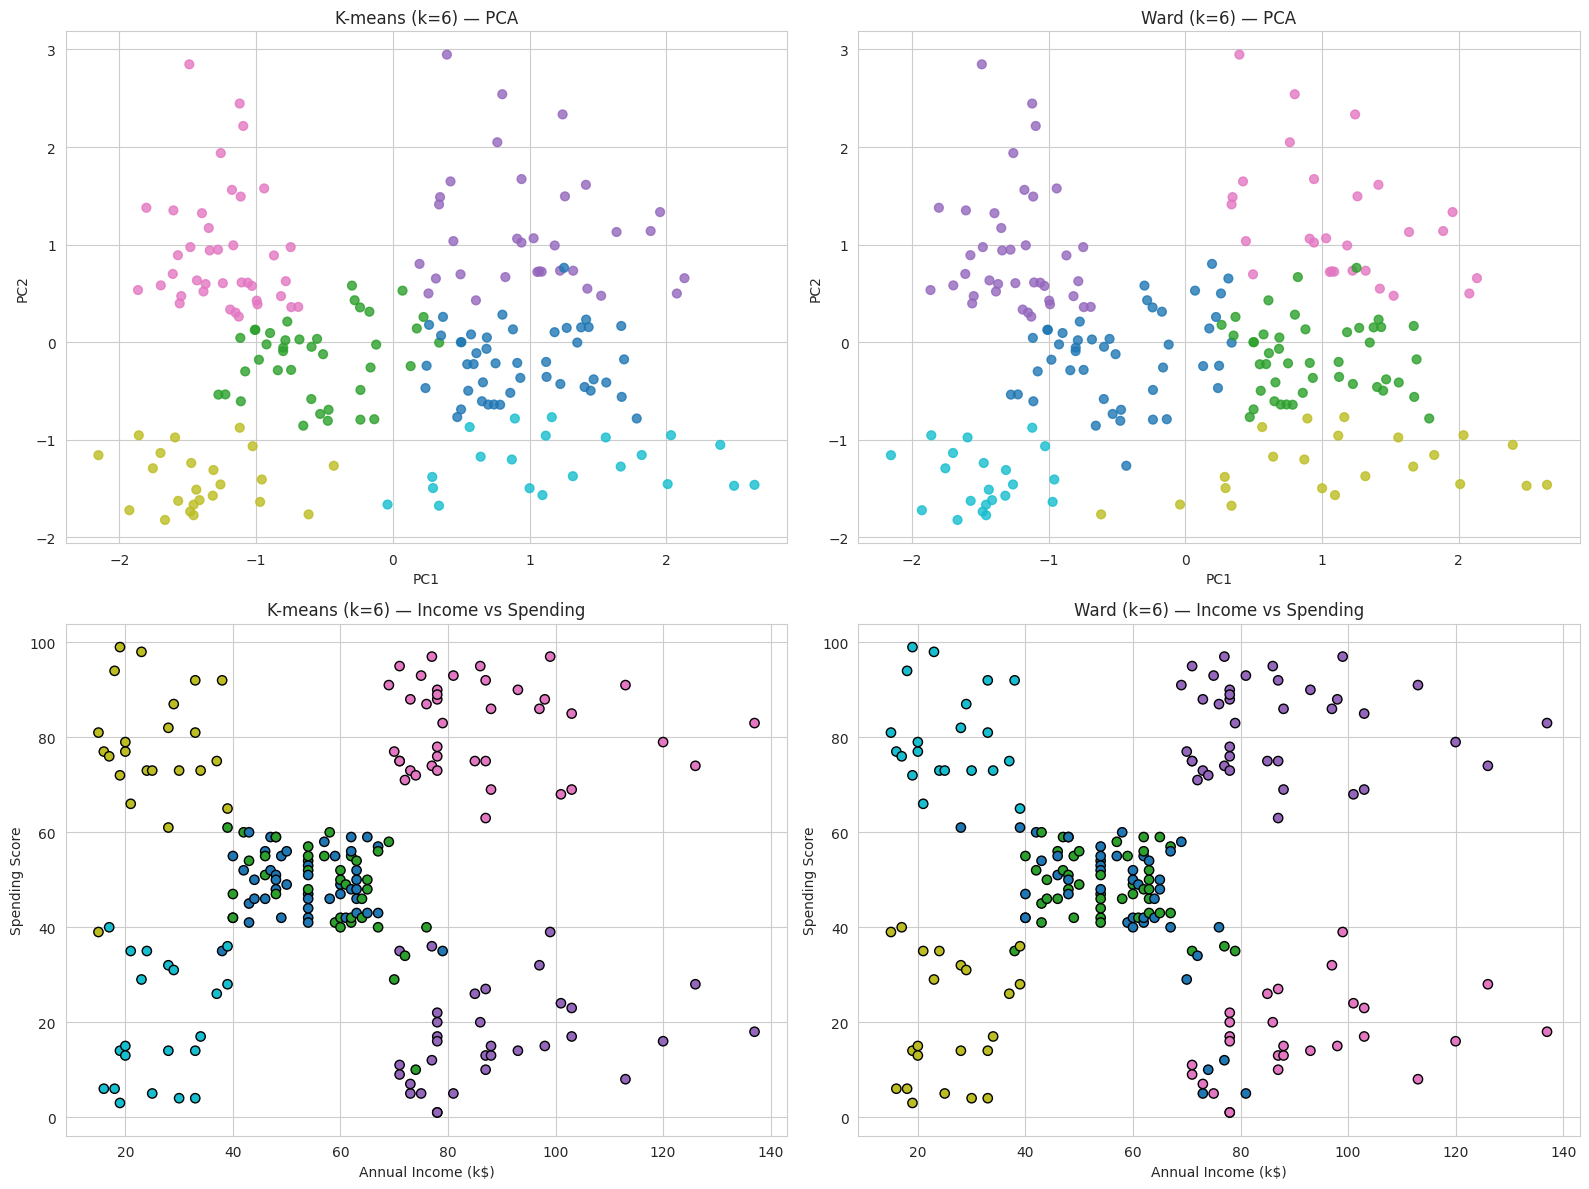

In [32]:
# рса
pca = PCA(n_components=2, random_state=RANDOM_STATE)
X_pca = pca.fit_transform(X_scaled)
print(f'Объяснённая дисперсия (2 PC): {pca.explained_variance_ratio_.sum():.3f}')

fig, axes = plt.subplots(2, 2, figsize=(16, 12))

# рса (k)
axes[0, 0].scatter(X_pca[:, 0], X_pca[:, 1], c=km_labels, cmap='tab10', s=40, alpha=0.8)
axes[0, 0].set_title(f'K-means (k={k_opt}) — PCA')
axes[0, 0].set_xlabel('PC1'); axes[0, 0].set_ylabel('PC2')

# рса(иерарх)
axes[0, 1].scatter(X_pca[:, 0], X_pca[:, 1], c=hc_labels, cmap='tab10', s=40, alpha=0.8)
axes[0, 1].set_title(f'Ward (k={k_opt}) — PCA')
axes[0, 1].set_xlabel('PC1'); axes[0, 1].set_ylabel('PC2')

# исходный (k)
axes[1, 0].scatter(df['Annual Income (k$)'], df['Spending Score (1-100)'],
                   c=km_labels, cmap='tab10', s=45, edgecolor='k')
axes[1, 0].set_title(f'K-means (k={k_opt}) — Income vs Spending')
axes[1, 0].set_xlabel('Annual Income (k$)'); axes[1, 0].set_ylabel('Spending Score')

# исходный (иерарх)
axes[1, 1].scatter(df['Annual Income (k$)'], df['Spending Score (1-100)'],
                   c=hc_labels, cmap='tab10', s=45, edgecolor='k')
axes[1, 1].set_title(f'Ward (k={k_opt}) — Income vs Spending')
axes[1, 1].set_xlabel('Annual Income (k$)'); axes[1, 1].set_ylabel('Spending Score')

plt.tight_layout(); plt.show()

### Визуализация полученных кластеров

В ходе исследования были применены два метода кластеризации: K-means и иерархическая кластеризация методом Уорда при количестве кластеров (k=6). Для оценки результатов использовались визуализации в пространстве главных компонент (PCA) и в плоскости признаков Доход и Расходы».

Проекция на первые две главные компоненты сохраняет 77,6% общей дисперсии данных, что позволяет достаточно полно отобразить структуру сформированных кластеров. Анализ полученных визуализаций показал наличие нескольких устойчивых групп клиентов, различающихся уровнем дохода и потребительской активностью.
Результаты кластеризации, полученные методами K-means и Ward, оказались практически идентичными. Оба алгоритма выделили схожие сегменты клиентов и продемонстрировали близкое распределение объектов по кластерам. Наиболее отчётливо выделяются группы клиентов с высоким уровнем дохода и расходов, высоким доходом и низкими расходами, а также сегменты с низкими значениями данных показателей.

Незначительные различия между методами наблюдаются только для отдельных объектов, расположенных вблизи границ кластеров, однако общая структура сегментации остаётся неизменной. Это свидетельствует о стабильности выявленной кластерной структуры и подтверждает корректность выбранного количества кластеров.

Таким образом, проведённый анализ позволил выделить шесть относительно однородных групп клиентов и показал, что результаты сегментации не зависят существенно от выбранного алгоритма кластеризации. Полученные кластеры могут быть использованы для дальнейшего анализа клиентского поведения и разработки маркетинговых стратегий.


Профили кластеров: K-means
  Age  Annual Income (k$)  Spending Score (1-100)  size                                        segment
56.33               54.27                   49.07    45   Низкий доход, низкие траты (старше среднего)
26.79               57.10                   48.13    39   Низкий доход, низкие траты (моложе среднего)
41.94               88.94                   16.97    33  Высокий доход, низкие траты (старше среднего)
32.69               86.54                   82.13    39 Высокий доход, высокие траты (моложе среднего)
25.00               25.26                   77.61    23  Низкий доход, высокие траты (моложе среднего)
45.52               26.29                   19.38    21   Низкий доход, низкие траты (старше среднего)


Профили кластеров: Ward
  Age  Annual Income (k$)  Spending Score (1-100)  size                                        segment
27.38               57.51                   45.84    45   Низкий доход, низкие траты (моложе среднего)
56.40               

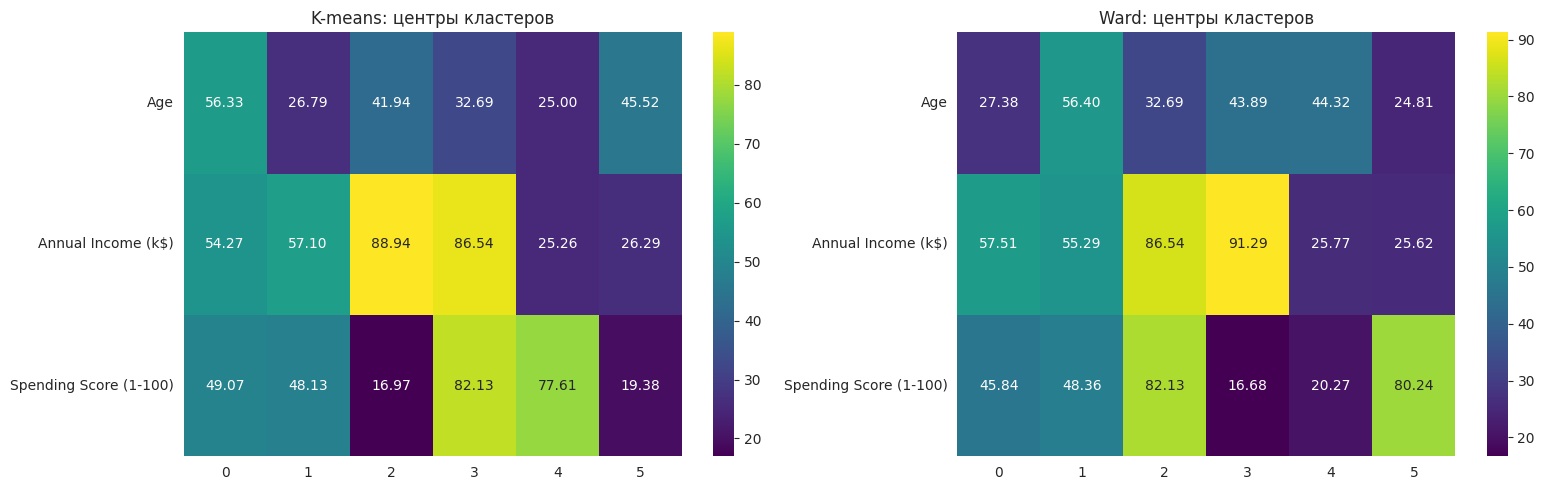

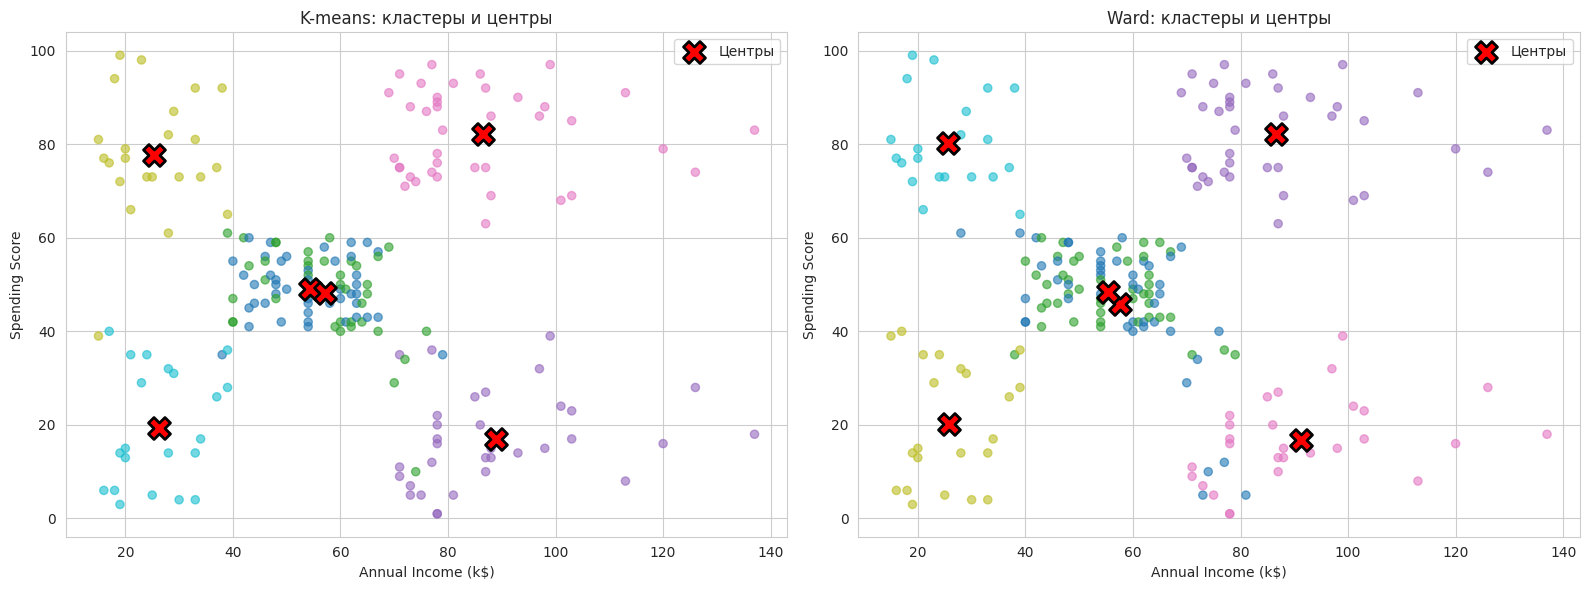

In [33]:
def label_segment(row):
    inc_med = X['Annual Income (k$)'].median()
    sp_med  = X['Spending Score (1-100)'].median()
    age_med = X['Age'].median()
    inc = 'Высокий доход' if row['Annual Income (k$)'] > inc_med else 'Низкий доход'
    sp  = 'высокие траты' if row['Spending Score (1-100)'] > sp_med else 'низкие траты'
    age = 'старше' if row['Age'] > age_med else 'моложе'
    return f'{inc}, {sp} ({age} среднего)'

prof_km = centers_km.copy()
prof_km['size'] = pd.Series(km_labels).value_counts().sort_index().values
prof_km['segment'] = prof_km.apply(label_segment, axis=1)

prof_hc = centers_hc.copy()
prof_hc['size'] = pd.Series(hc_labels).value_counts().sort_index().values
prof_hc['segment'] = prof_hc.apply(label_segment, axis=1)

print('Профили кластеров: K-means')
print(prof_km.round(2).to_string(index=False))

print('\n')
print('Профили кластеров: Ward')
print(prof_hc.round(2).to_string(index=False))

fig, axes = plt.subplots(1, 2, figsize=(16, 5))
sns.heatmap(prof_km[features].T, annot=True, cmap='viridis', fmt='.2f', ax=axes[0])
axes[0].set_title('K-means: центры кластеров')
sns.heatmap(prof_hc[features].T, annot=True, cmap='viridis', fmt='.2f', ax=axes[1])
axes[1].set_title('Ward: центры кластеров')
plt.tight_layout(); plt.show()

fig, axes = plt.subplots(1, 2, figsize=(16, 6))
for ax, labels, centers, title in [
    (axes[0], km_labels, centers_km, 'K-means'),
    (axes[1], hc_labels, centers_hc, 'Ward')
]:
    ax.scatter(df['Annual Income (k$)'], df['Spending Score (1-100)'],
               c=labels, cmap='tab10', s=35, alpha=0.6)
    ax.scatter(centers['Annual Income (k$)'], centers['Spending Score (1-100)'],
               c='red', marker='X', s=250, edgecolor='black', linewidth=2, label='Центры')
    ax.set_title(f'{title}: кластеры и центры')
    ax.set_xlabel('Annual Income (k$)'); ax.set_ylabel('Spending Score')
    ax.legend()
plt.tight_layout(); plt.show()

### Интерпретация центров кластеров и анализ тепловых карт

Для наглядной интерпретации полученных групп были построены тепловые карты (heatmap) центров кластеров и scatter-графики с наложением центроидов.

**1. Анализ тепловых карт (средние значения признаков):**
Яркие цвета на карте (желтый — максимум, темно-фиолетовый — минимум) позволяют четко описать каждый сегмент клиентов (на примере K-Means):

**Кластер 0:** Средний возраст (56 лет), средний доход (54k), умеренные траты (49).

**Кластер 1:** Молодые (26 лет), средний доход (57k), средние траты (~8). Вместе с кластером 0 образуют плотное ядро в центре графика.

**Кластер 2:** Средний возраст (41 год), высокий доход (88k), но крайне низкие траты (16). Предпочитают не тратить деньги.

**Кластер 3:** Средний возраст (32 года), высокий доход (86k) и максимальные траты (82). Самая ценная целевая аудитория.

**Кластер 4:** Очень молодые (25 лет), низкий доход (25k), но высокие траты (77). Тратят больше, чем позволяет их доход.

**Кластер 5:** Средний возраст (45 лет), низкий доход (26k) и низкие траты (19). Покупают только самое необходимое. <br><br>

**2. Расположение центроидов (Scatter-графики):**

На графиках красные крестики показывают центры кластеров. У K-Means центроиды расположены строго в геометрическом центре «облаков» точек. У Ward центры также находятся внутри групп, подтверждая, что оба алгоритма нашли одинаковые плотные области в пространстве признаков (Доход — Траты).

**Вывод:** Тепловые карты подтверждают, что K-Means и Ward выделили практически идентичные по смыслу сегменты. Это означает, что найденная структура клиентов  является объективной особенностью данных, а не случайностью конкретного алгоритма.

# Заключение
В ходе выполнения лабораторной работы была успешно решена задача кластеризации клиентов торгового центра с использованием методов машинного обучения без учителя.

Основные результаты работы:

1. Подготовка данных: Проведен анализ, в ходе которого были проверены пропуски (отсутствуют) и выбросы (найдено 2 аномалии в признаке дохода, которые не требуют удаления). Для корректной работы алгоритмов данные были стандартизированы с помощью StandardScaler.

2. Выбор оптимального числа кластеров: С использованием метода локтя (Inertia) и метрики Silhouette Score было определено оптимальное количество кластеров
k=6. Дендрограмма иерархической кластеризации визуально подтвердила это разбиение.

3. Сравнение алгоритмов: Были обучены две модели — K-Means и Иерархическая кластеризация (метод Ward).

4. Оба метода показали высокую степень согласованности (индекс ARI = 0.891), что подтверждает объективность найденной структуры.

5. По внутренним метрикам (Silhouette Score = 0.428, Davies-Bouldin = 0.825, Calinski-Harabasz = 135.1) K-Means показал немного лучшие результаты, создав более компактные и четко разделенные кластеры.

6. Интерпретация результатов: Анализ центров кластеров и тепловых карт позволил выделить 6 четких сегментов клиентов: от богатых и молодежи до богатых экономов и консерваторов. Такая сегментация может быть использована для разработки персонализированных маркетинговых стратегий.

Визуализация: Применение метода главных компонент (PCA) позволило визуализировать результаты кластеризации в двумерном пространстве (с сохранением 77.6% дисперсии), что наглядно подтвердило разделимость полученных групп.

Вывод: Цель работы достигнута. В ходе исследования было доказано, что алгоритм K-Means является предпочтительным для данной задачи благодаря более высоким метрикам качества, простоте интерпретации и скорости работы. Разработанная модель сегментации клиентов может быть применена в реальной деятельности торгового предприятия для оптимизации ассортимента и повышения эффективности маркетинга.